# 02 · Candidates, match scoring, thresholds and evaluation

Pipeline (`src/train.py`):
1. **Candidate generation** (`candidates.py`): keep an open invoice if the remittance references it, its customer fuzzy-matches the payer, or its amount equals the payment.
2. **Pair features** (`features.py`): reference hits, name similarity, amount ratio / fee / discount patterns, *subset-sum* membership for combined payments, timing, context.
3. **Model**: logistic regression vs histogram gradient boosting, against an ERP-style **rules** baseline.
4. **Decision layer** (`decide.py`): AUTO_MATCH / REVIEW / UNAPPLIED; the auto-match threshold is picked on validation by expected cost with a 99.5 % precision floor.

Split is by payment date: train Jan–Aug, validation Sep–Oct, test Nov onward. Run `python src/train.py` and `python src/evaluate.py` first; this notebook reads their outputs.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160)
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "figure.dpi": 100})
from IPython.display import Image
RES, MOD = ROOT / "results", ROOT / "models"
meta = json.loads((MOD / "model_meta.json").read_text())
print("chosen model:", meta["model"], "| auto threshold:", meta["auto_threshold"], "| candidate recall:", meta["candidate_recall"])

chosen model: hgb | auto threshold: 0.5 | candidate recall: {'test': 0.9958, 'train': 0.9906, 'val': 0.9936}


## Step 1: candidate generation
Recall matters most here: an invoice dropped at this step can never be matched. The shortlist keeps ~99.4 % of true links with ~24 candidates per payment.

In [2]:
pairs = pd.read_csv(RES / "pairs.csv.gz")
per = pairs.groupby("payment_id").size()
print(f"{len(pairs):,} pairs | median {per.median():.0f} candidates per payment | positives {pairs.is_match.mean():.1%}")
src = pairs.groupby("source").is_match.agg(["size", "mean"]).sort_values("size", ascending=False)
src.columns = ["pairs", "share that are true matches"]; display(src.round(3))

200,730 pairs | median 17 candidates per payment | positives 5.3%


,pairs,share that are true matches
source,,
name,144999,0.013
amount,46197,0.001
name+ref,3452,1.000
amount+name+ref,3421,1.000
amount+name,2082,0.701
ref,446,0.352
amount+ref,133,0.992


## Step 2: the features for one combined payment
The `subset_match` feature flags invoices that belong to a combination of the customer's open invoices whose total equals the payment (or equals it after a 2 % discount).

In [3]:
pid = pairs[(pairs.payment_type == "combined")].payment_id.iloc[5]
cols = ["invoice_number", "customer_id", "open_amount", "payment_amount", "ref_exact", "name_score", "subset_match",
        "subset_size", "days_from_due", "is_match"]
display(pairs[pairs.payment_id == pid].sort_values("is_match", ascending=False)[cols].head(10))

,invoice_number,customer_id,open_amount,payment_amount,ref_exact,name_score,subset_match,subset_size,days_from_due,is_match
2,INV-100004,C1157,1919.16,6729.61,0,89.06250,1,3,-11.0,1
4,INV-100326,C1157,1648.51,6729.61,0,89.06250,1,3,-20.0,1
5,INV-100534,C1157,3161.94,6729.61,0,89.06250,1,3,-27.0,1
3,INV-100197,C1292,670.77,6729.61,0,78.62069,0,0,-16.0,0
6,INV-100546,C1157,1444.24,6729.61,0,89.06250,0,0,-27.0,0
7,INV-100638,C1292,846.85,6729.61,0,78.62069,0,0,-30.0,0


## Step 3: model comparison on validation
Gradient boosting wins clearly on pair-level PR-AUC and, more importantly, on how many payments it can auto-match at the precision floor. Rules are perfectly precise but leave ~40 % of payments for people.

In [4]:
val = pd.read_csv(RES / "val_model_comparison.csv")
display(val[["model", "pair_pr_auc", "pair_roc_auc", "auto_threshold", "auto_match_rate", "auto_match_precision",
             "review_rate", "unapplied_rate"]].round(4))

,model,pair_pr_auc,pair_roc_auc,auto_threshold,auto_match_rate,auto_match_precision,review_rate,unapplied_rate
0,logreg,0.9690,0.9968,0.63,0.7937,1.0000,0.1470,0.0592
1,hgb,0.9889,0.9993,0.50,0.8543,0.9992,0.0978,0.0479
2,rules,NaN,NaN,NaN,0.6041,1.0000,0.3959,0.0000


## Step 4: choosing the auto-match threshold
Each manual payment costs about \\$5 of analyst time; a wrong auto-match costs about \\$150 to reverse and re-apply (and can trigger a wrong dunning letter). The cheapest threshold that still meets 99.5 % precision is chosen. Here precision is already above the floor at the lowest threshold because the *amount reconciliation* check filters most risky matches, so extra strictness only adds manual work.

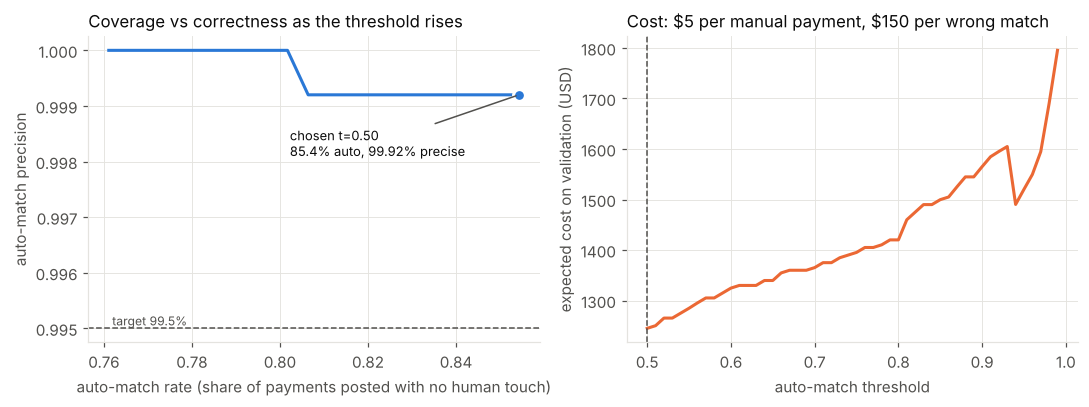

In [5]:
display(Image(RES / "threshold_tradeoff.png"))

## Test results (reported once)

In [6]:
test = pd.read_csv(RES / "test_metrics.csv").set_index("model").T
display(test)

model,hgb + decision layer,rules
payments,2190.0000,2190.0000
auto_match_rate,0.8616,0.6055
auto_match_precision,0.9963,1.0000
auto_matched_wrong,7.0000,0.0000
review_rate,0.0890,0.3945
review_top1_suggestion_correct,0.8649,0.0000
unapplied_rate,0.0493,0.0000
unapplied_truly_unmatched,0.7500,NaN
matchable_payments_auto_matched,0.8961,0.6320


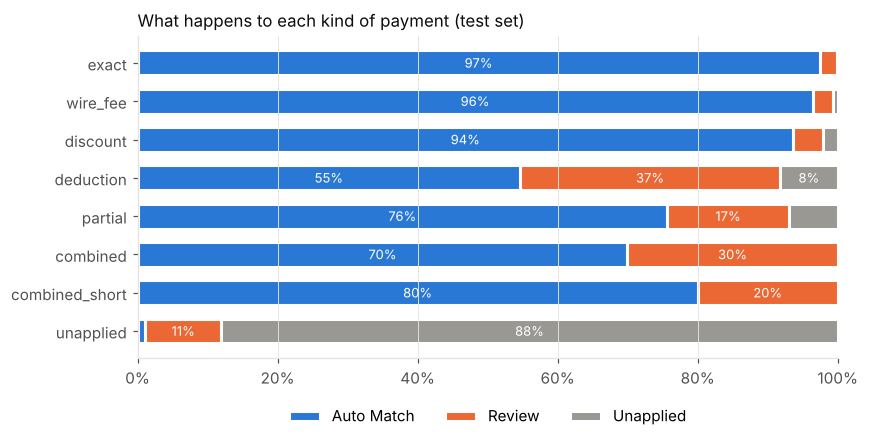

,payment_type,payments,auto_match_rate,auto_match_precision,review_rate,unapplied_rate
0,exact,1309,0.974,1.000,0.024,0.002
1,wire_fee,139,0.964,0.993,0.029,0.007
2,discount,94,0.936,1.000,0.043,0.021
3,deduction,97,0.546,1.000,0.371,0.082
4,partial,201,0.756,0.993,0.174,0.070
5,combined,223,0.700,0.974,0.300,0.000
6,combined_short,35,0.800,1.000,0.200,0.000
7,unapplied,92,0.011,0.000,0.109,0.880


In [7]:
display(Image(RES / "decision_mix_by_type.png"))
display(pd.read_csv(RES / "metrics_by_payment_type.csv"))

Exact payments, fees and discounts are almost fully automated. Deductions and combined payments go to review more often, which is the right behaviour: a short payment usually needs a dispute or deduction code, and a combined payment needs every invoice right.

## Pair-level quality and calibration

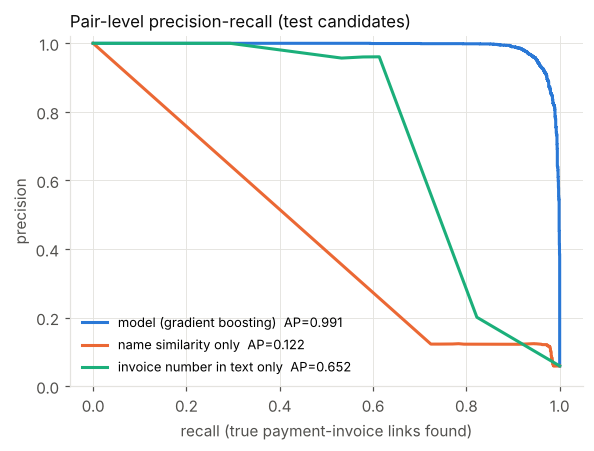

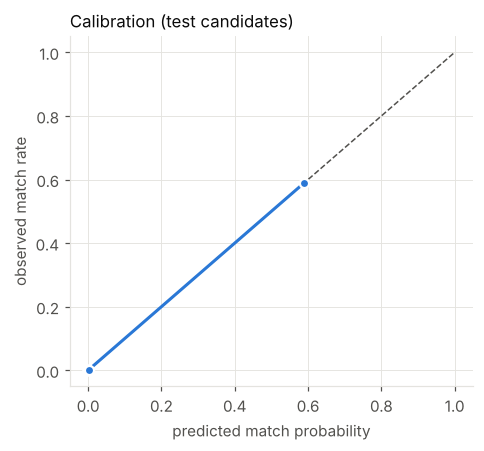

In [8]:
display(Image(RES / "pr_curve.png")); display(Image(RES / "calibration.png"))

## What drives the model
Permutation importance on test pairs: the invoice number in the remittance and whether this customer is the *best* name match dominate, followed by amount closeness and subset-sum membership.

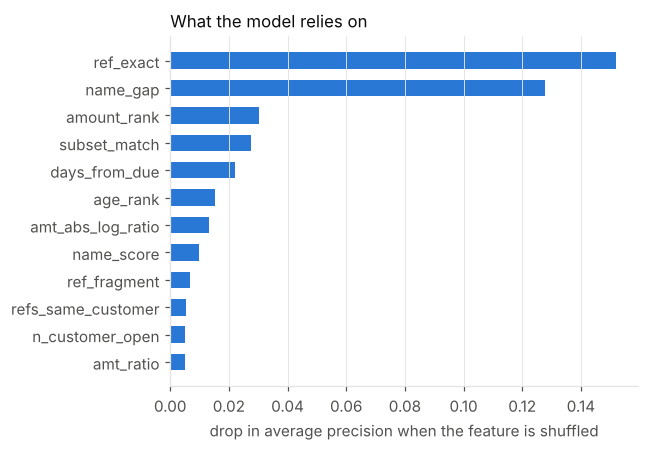

In [9]:
display(Image(RES / "feature_importance.png"))

## Error analysis: every wrong auto-match on test

In [10]:
err = pd.read_csv(RES / "auto_match_errors.csv", keep_default_na=False)
display(err)

,payment_id,payment_type,amount,payer_name,remittance_text,invoices,true_invoices,confidence,reconciliation
0,P006478,combined,2022.40,Sunrise Engineering Li,SEE EMAIL,INV-108425,INV-108017|INV-108399,0.9296,fee
1,P007238,combined,9856.38,ACME LOGISTICS,"PAYMENT 109843, INV 109195",INV-109843|INV-109710|INV-109623,INV-109843|INV-109915,0.7755,discount
2,P007354,partial,473.25,FRONTIER HOSPITALITY GROUP,ACCOUNT SETTLEMENT,INV-108765,INV-108508,0.6700,fee
3,P007558,wire_fee,955.00,ACH CREDIT,Pmt for INV 109695,INV-109695,INV-109659,0.7976,partial
4,P007686,unapplied,6393.37,Pioneer Chemicals HLDGS,ADVANCE PMT,INV-109362|INV-109482,,0.6042,discount
5,P007938,combined,22649.75,Cascade Pharmaceutical,Pmt for PO 4302709/PO 4504517,INV-109410|INV-109403|INV-109611,INV-109403|INV-109410,0.8215,discount
6,P008024,combined,39616.07,VERTEX HOSP GORUP,INVOICES INV 101043; INV110108; 110115,INV-110108|INV-110115|INV-110043|INV-110385,INV-110043|INV-110108|INV-110115,0.9514,discount


Seven wrong auto-matches out of ~1,890, in three patterns:
* **Wrong subset of a combined payment (4 of 7).** A different combination of the customer's open invoices adds up to the payment, exactly or after the 2 % discount tolerance, so the amount check passes for the wrong set.
* **No reference, near-identical amount (2 of 7).** With "SEE EMAIL" or "ACCOUNT SETTLEMENT" as the only text, an invoice whose amount is within the 50 fee tolerance wins.
* **A typo that hits a real invoice number (1 of 7).** "INV 109695" was meant to be 109659, but 109695 also exists and is open; the partial-payment rule then applied it. A prepayment that happens to equal two open invoices less 2 % is a similar coincidence.

Mitigations worth trying: for combined payments, auto-match only when the subset is unique; require the payer name to agree before applying a partial; add customer history features (does this customer usually batch or take discounts?); and route high-value payments to review regardless of score.

## Business impact

In [11]:
bi = pd.read_csv(RES / "business_impact.csv")
display(bi)
ml, rules = bi.iloc[0], bi.iloc[1]
print(f"At 50,000 payments a year: {rules.manual_payments_per_year - ml.manual_payments_per_year:,.0f} fewer manual payments,"
      f" about {ml.hours_saved_vs_rules:,.0f} analyst hours saved vs the rules engine.")

,approach,auto_match_rate,auto_match_precision,manual_payments_per_year,analyst_hours_per_year,wrong_auto_matches_per_year,hours_saved_vs_rules
0,hgb + decision layer,0.8616,0.9963,6915,691,159,1281
1,rules,0.6055,1.0000,19725,1972,0,0


At 50,000 payments a year: 12,810 fewer manual payments, about 1,281 analyst hours saved vs the rules engine.
